# UPI Payments Intelligence
A guided notebook for Dhananjay. Run from top to bottom. The included outputs were executed against the packaged CSV snapshot. Source dates and limitations are part of the analysis.

**Decision:** Where should a payments operations team investigate capacity, merchant activity and technical declines?

**Grain:** one national month, one merchant category-month, one bank-role-month, one state-month. There are no individual customer transactions.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import sqlite3
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if not (ROOT / 'src' / 'pipeline.py').exists():
    raise FileNotFoundError('Open this notebook inside the extracted project folder.')
sys.path.insert(0, str(ROOT / 'src'))
import pipeline
print('Project:', ROOT.name)


Project: upi-payments-intelligence


## 1. Read and validate
`read_csv` brings the snapshots into DataFrames. Cleaning standardizes dates and units. Validation checks uniqueness before joins, so a repeated key cannot silently multiply totals. Five recent national months override rounded values with official NPCI figures.

In [2]:
monthly, merchants, banks, states = pipeline.clean_data()
print('Shapes:', {k: v.shape for k,v in [('monthly',monthly),('merchants',merchants),('banks',banks),('states',states)]})
print(monthly.tail(5).to_string(index=False))


Shapes: {'monthly': (48, 13), 'merchants': (29, 12), 'banks': (12, 11), 'states': (37, 9)}
     month  volume_mn   value_cr  banks_live source_id        precision  days_in_month  daily_volume_mn  avg_ticket_inr  mom_volume  mom_daily_volume  yoy_volume  rolling_3m_volume_mn
2026-04-01   22346.80 2902988.05       713.0        S1 primary_verified             30       744.893333     1299.062080   -0.012951          0.019951    0.249122          21792.266667
2026-05-01   23201.93 2990424.21       720.0        S1 primary_verified             31       748.449355     1288.868732    0.038266          0.004774    0.242073          22729.576667
2026-06-01   22716.07 2892138.67       731.0        S1 primary_verified             30       757.202333     1273.168585   -0.020940          0.011695    0.234569          22754.933333
2026-07-01   23658.35 2987880.49       741.0        S1 primary_verified             31       763.172581     1262.928518    0.041481          0.007885    0.215118          23

## 2. Understand NumPy and vectorization
A crore is 10 million. Therefore average ticket in INR is `10 * value_cr / volume_mn`. Vectorized operations calculate a whole column. `np.select` assigns merchant segments using median observed volume and whether reported growth is negative. These segments are analyst rules, not source classifications.

In [3]:
manual_ticket = 10 * monthly.iloc[-1]['value_cr'] / monthly.iloc[-1]['volume_mn']
print('Latest average ticket:', round(manual_ticket, 2))
print(merchants.groupby('segment').agg(categories=('mcc','count'), volume_mn=('volume_mn','sum')).to_string())


Latest average ticket: 1216.84
                         categories  volume_mn
segment                                       
Larger and contracting            3     1185.4
Larger and growing               12    10012.7
Smaller and contracting           6      565.2
Smaller and growing               8      771.0


## 3. Ask better growth questions
`pct_change()` calculates month-over-month change. A 30-day month has fewer processing days than a 31-day month, so compare the daily run rate too. `pct_change(12)` requires a complete monthly index. Missing first-year comparisons remain missing.

In [4]:
print(monthly[['month','volume_mn','mom_volume','mom_daily_volume','yoy_volume']].tail(8).to_string(index=False))


     month  volume_mn  mom_volume  mom_daily_volume  yoy_volume
2026-01-01   21700.00    0.003236          0.003236    0.276471
2026-02-01   20390.00   -0.060369          0.040306    0.265673
2026-03-01   22640.00    0.110348          0.002895    0.237158
2026-04-01   22346.80   -0.012951          0.019951    0.249122
2026-05-01   23201.93    0.038266          0.004774    0.242073
2026-06-01   22716.07   -0.020940          0.011695    0.234569
2026-07-01   23658.35    0.041481          0.007885    0.215118
2026-08-01   24508.96    0.035954          0.035954    0.224836


## 4. Rank operational review by affected volume
Technical decline is a failure associated with system/network issues. Estimated declines = attempts × TD rate. Use a weighted rate for a selected sample. The two displayed bank samples are selected and incomplete: neither is a national estimate, and sending plus receiving must not be added.

In [5]:
sending = banks[banks['role'].eq('Sending')].copy()
sending = sending.sort_values('estimated_td_mn', ascending=False)
print(sending[['bank','volume_mn','td_rate','estimated_td_mn','scenario_avoided_mn']].to_string(index=False))
print('Weighted sample TD:', np.average(sending['td_rate'], weights=sending['volume_mn']))


                           bank  volume_mn  td_rate  estimated_td_mn  scenario_avoided_mn
          Central Bank of India      478.3   0.0234         11.19222             4.400360
               Baroda U.P. Bank      109.7   0.0244          2.67668             1.064090
           Punjab and Sind Bank       76.9   0.0195          1.49955             0.557525
     NSDL Payments Bank Limited       85.1   0.0117          0.99567             0.285085
Rajasthan Marudhara Gramin Bank       78.5   0.0118          0.92630             0.266900
        Maharashtra Gramin Bank       45.9   0.0123          0.56457             0.167535
Weighted sample TD: 0.02041970494053065


## 5. Join with SQL
The pipeline writes a local SQLite database automatically. A bank dimension holds its name once; fact rows contain its key and measures. MySQL users can import `sql/mysql_import.sql` into the dedicated `upi_portfolio` database and run the same analysis queries.

In [6]:
with sqlite3.connect(ROOT / 'data' / 'upi_intelligence.sqlite') as con:
    q = '''SELECT b.bank, f.role, f.volume_mn*f.td_rate AS estimated_td_mn
           FROM fact_bank f JOIN dim_bank b ON f.bank_id=b.bank_id
           WHERE f.role='Sending' ORDER BY estimated_td_mn DESC'''
    result = pd.read_sql_query(q, con)
print(result.to_string(index=False))


                           bank    role  estimated_td_mn
          Central Bank of India Sending         11.19222
               Baroda U.P. Bank Sending          2.67668
           Punjab and Sind Bank Sending          1.49955
     NSDL Payments Bank Limited Sending          0.99567
Rajasthan Marudhara Gramin Bank Sending          0.92630
        Maharashtra Gramin Bank Sending          0.56457


## 6. Treat missing geography as a finding
Compare each state row to the same month’s national total. Preserve Unclassified. Rounded rows may not add perfectly to the official total; a residual is not proof that the network lost transactions.

In [7]:
print(states[states['state'].isin(['Uttar Pradesh','Unclassified'])][['state','volume_mn','national_volume_share']].to_string(index=False))
print('Rounding residual, million:', round(states['volume_mn'].sum()-monthly.iloc[-1]['volume_mn'], 3))


        state  volume_mn  national_volume_share
Uttar Pradesh     1260.0               0.051410
 Unclassified    10880.0               0.443919
Rounding residual, million: 0.44


## 7. Forecast without using future observations
Three candidates: last-month daily rate, last-year daily rate, and a 12-month log-linear trend. The first 30 months form the initial history; the next six select the model; the final 12 evaluate it. Each prediction refits using earlier months only. WAPE = total absolute error / total actual volume. The ±10% next-month range is an assumption, not a confidence interval. This is a retrospective exercise using the current data vintage.

In [8]:
predictions, metrics, next_month = pipeline.forecasting(monthly)
print(metrics[['split','model','months','mae_mn','wape']].to_string(index=False))
print(next_month.to_string(index=False))


     split                model  months      mae_mn     wape
      test          daily_naive      12  363.962713 0.016569
      test        log_trend_12m      12  247.051240 0.011247
      test seasonal_daily_naive      12 4491.842500 0.204491
validation          daily_naive       6  359.527522 0.019132
validation        log_trend_12m       6  298.959154 0.015909
validation seasonal_daily_naive       6 4780.000000 0.254368
     month         model  forecast_mn  assumed_minus_10pct_mn  assumed_plus_10pct_mn                                                   range_type
2026-09-01 log_trend_12m 23986.802253            21588.122027           26385.482478 Assumed +/-10% planning scenarios; not a prediction interval


## 8. Turn findings into actions
Write an observation, implication, recommended investigation and evidence needed. Example: high estimated bank declines justify investigation of that bank’s error logs. Aggregate data cannot reveal the root cause or prove recoverable revenue.

**Exercises:** (1) Reproduce the latest ticket without copying the answer. (2) Explain why a simple average TD is wrong. (3) Change the hypothetical target to 1% and rerun. (4) Rebuild SQL Q07 yourself. (5) Explain why merchant totals cannot be called total UPI. (6) Make a baseline forecast manually before reading the trend code.

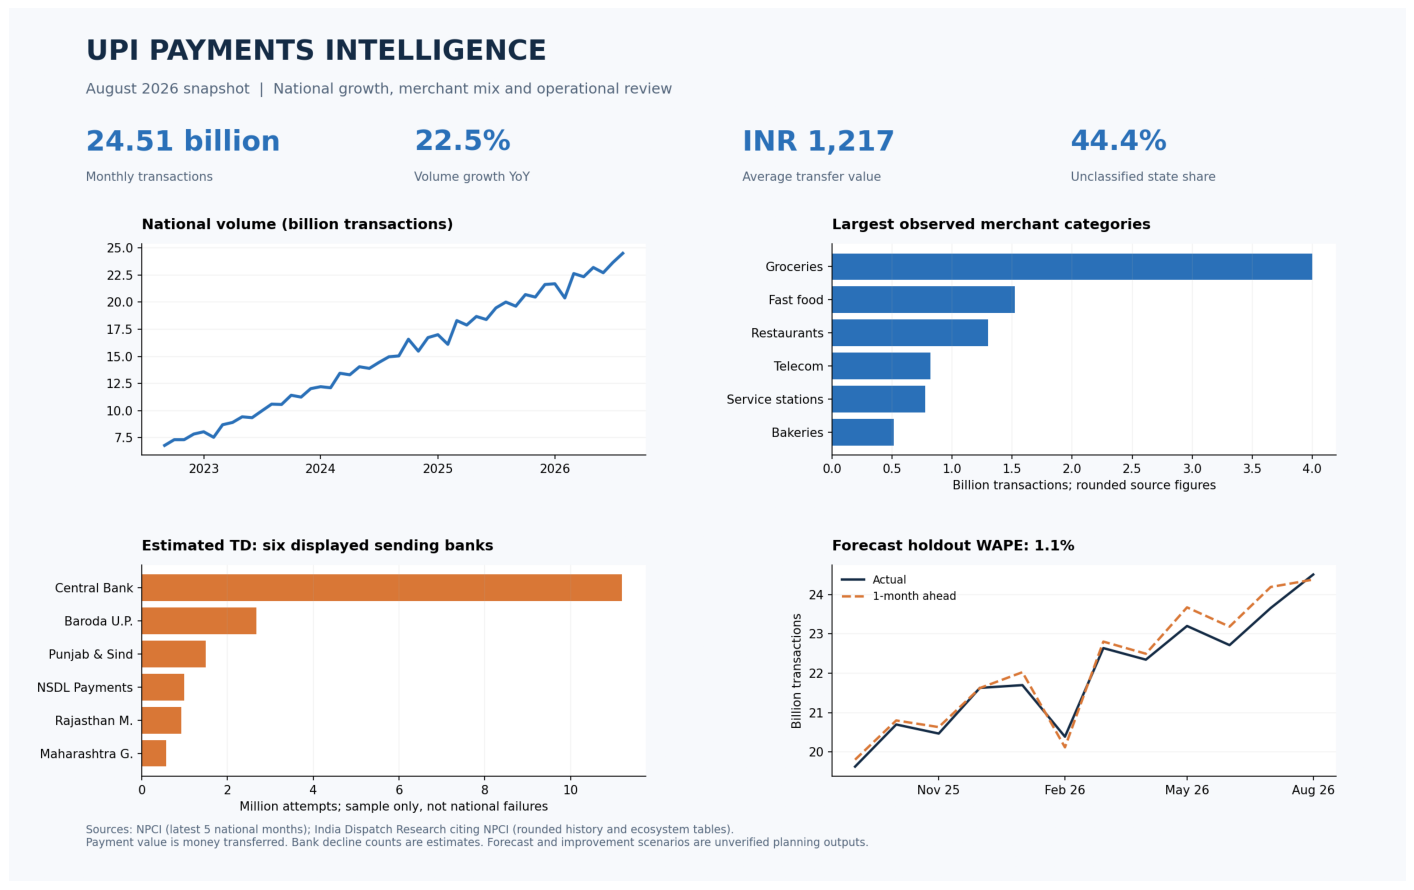

In [9]:
from matplotlib import pyplot as plt
img = plt.imread(ROOT / 'reports' / 'dashboard.png')
plt.figure(figsize=(16,10))
plt.imshow(img)
plt.axis('off')
plt.tight_layout()
plt.show()
